**Generative AI Use**: For the purposes of the assignments, the use of generative AI is subject to the same policies regarding collaboration. Just as with other collaborators, each student must write down the solutions independently of the output of the interaction and the submission should include a note denoting the nature of the collaboration. The use of generative AI tools to substantially complete sections of the assignments is not in line with the spirit of the assignments, and would be a violation of the [Honor Code](https://communitystandards.stanford.edu/policies-and-guidance/honor-code).

In [3]:
import os
import sys

FOLDERNAME = r'C:\Users\11984\Desktop\Stanford 231n\assignment1'

os.chdir(FOLDERNAME)
sys.path.insert(0, FOLDERNAME)

print("当前目录：", os.getcwd())

当前目录： C:\Users\11984\Desktop\Stanford 231n\assignment1


# Image features exercise
*Complete and hand in this completed worksheet (including its outputs and any supporting code outside of the worksheet) with your assignment submission. For more details see the [assignments page](http://vision.stanford.edu/teaching/cs231n/assignments.html) on the course website.*

We have seen that we can achieve reasonable performance on an image classification task by training a linear classifier on the pixels of the input image. In this exercise we will show that we can improve our classification performance by training linear classifiers not on raw pixels but on features that are computed from the raw pixels.

All of your work for this exercise will be done in this notebook.

In [8]:
import random
import numpy as np
from cs231n.data_utils import load_CIFAR10
import matplotlib.pyplot as plt

%matplotlib inline

plt.rcParams['figure.figsize'] = (10.0, 8.0)
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

## Load data
Similar to previous exercises, we will load CIFAR-10 data from disk.

In [12]:
%pip install future
from cs231n.features import color_histogram_hsv, hog_feature

def get_CIFAR10_data(num_training=49000, num_validation=1000, num_test=1000):
    # Load the raw CIFAR-10 data
    cifar10_dir = 'cs231n/datasets/cifar-10-batches-py'

    # Cleaning up variables to prevent loading data multiple times (which may cause memory issue)
    try:
       del X_train, y_train
       del X_test, y_test
       print('Clear previously loaded data.')
    except:
       pass

    X_train, y_train, X_test, y_test = load_CIFAR10(cifar10_dir)

    # Subsample the data
    mask = list(range(num_training, num_training + num_validation))
    X_val = X_train[mask]
    y_val = y_train[mask]
    mask = list(range(num_training))
    X_train = X_train[mask]
    y_train = y_train[mask]
    mask = list(range(num_test))
    X_test = X_test[mask]
    y_test = y_test[mask]

    return X_train, y_train, X_val, y_val, X_test, y_test

X_train, y_train, X_val, y_val, X_test, y_test = get_CIFAR10_data()

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: C:\Users\11984\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


## Extract Features
For each image we will compute a Histogram of Oriented
Gradients (HOG) as well as a color histogram using the hue channel in HSV
color space. We form our final feature vector for each image by concatenating
the HOG and color histogram feature vectors.

Roughly speaking, HOG should capture the texture of the image while ignoring
color information, and the color histogram represents the color of the input
image while ignoring texture. As a result, we expect that using both together
ought to work better than using either alone. Verifying this assumption would
be a good thing to try for your own interest.

The `hog_feature` and `color_histogram_hsv` functions both operate on a single
image and return a feature vector for that image. The extract_features
function takes a set of images and a list of feature functions and evaluates
each feature function on each image, storing the results in a matrix where
each column is the concatenation of all feature vectors for a single image.

In [ ]:
from cs231n.features import *

# num_color_bins = 10 # Number of bins in the color histogram
num_color_bins = 25 # Number of bins in the color histogram
feature_fns = [hog_feature, lambda img: color_histogram_hsv(img, nbin=num_color_bins)] #此处定义了特征提取函数列表，包含HOG特征和颜色直方图特征
X_train_feats = extract_features(X_train, feature_fns, verbose=True) #把训练集的特征提取出来
X_val_feats = extract_features(X_val, feature_fns)
X_test_feats = extract_features(X_test, feature_fns)

# Preprocessing: Subtract the mean feature
mean_feat = np.mean(X_train_feats, axis=0, keepdims=True)  #把训练集的特征均值计算出来，axis=0 表示沿着行的方向计算，keepdims=True 表示保留二维形式
X_train_feats -= mean_feat
X_val_feats -= mean_feat
X_test_feats -= mean_feat #把训练集的特征均值从训练集、验证集和测试集的特征中减去，实现特征中心化

# Preprocessing: Divide by standard deviation. This ensures that each feature
# has roughly the same scale.
std_feat = np.std(X_train_feats, axis=0, keepdims=True) #把训练集的特征标准差计算出来，axis=0 表示沿着行的方向计算，keepdims=True 表示保留二维形式
X_train_feats /= std_feat
X_val_feats /= std_feat
X_test_feats /= std_feat



Done extracting features for 1000 / 49000 images
Done extracting features for 2000 / 49000 images
Done extracting features for 3000 / 49000 images
Done extracting features for 4000 / 49000 images
Done extracting features for 5000 / 49000 images
Done extracting features for 6000 / 49000 images
Done extracting features for 7000 / 49000 images
Done extracting features for 8000 / 49000 images
Done extracting features for 9000 / 49000 images
Done extracting features for 10000 / 49000 images
Done extracting features for 11000 / 49000 images
Done extracting features for 12000 / 49000 images
Done extracting features for 13000 / 49000 images
Done extracting features for 14000 / 49000 images
Done extracting features for 15000 / 49000 images
Done extracting features for 16000 / 49000 images
Done extracting features for 17000 / 49000 images
Done extracting features for 18000 / 49000 images
Done extracting features for 19000 / 49000 images
Done extracting features for 20000 / 49000 images
Done extr

## Train Softmax classifier on features
Using the Softmax code developed earlier in the assignment, train Softmax classifiers on top of the features extracted above; this should achieve better results than training them directly on top of raw pixels.

In [ ]:
# Use the validation set to tune the learning rate and regularization strength

from cs231n.classifiers.linear_classifier import Softmax
import numpy as np

learning_rates = [1e-7, 1e-6]    
regularization_strengths = [5e5, 5e6]  #让W不要太大，太大导致过拟合

results = {}
best_val = -1
best_softmax = None

################################################################################
# TODO:                                                                        #
# Use the validation set to set the learning rate and regularization strength. #
# This should be identical to the validation that you did for the Softmax; save#
# the best trained classifer in best_softmax. If you carefully tune the model, #
# you should be able to get accuracy of above 0.42 on the validation set.      #
################################################################################
#生成one-hot编码的标签矩阵
N = y_train.shape[0] #每个样本的标签是一个整数，表示该样本所属的类别。N表示训练集的样本数量
C = 10

y_train_one_hot = np.zeros((N, C))
y_train_one_hot[np.arange(N), y_train] = 1 #行表示样本，列表示类别，y_train_one_hot[i, j] = 1 表示第 i 个样本属于第 j 个类别
print(y_train[:5])
print(y_train_one_hot[:5])
print(y_train_one_hot.shape)


# 初始化权重矩阵
print("训练集形状：", X_train_feats.shape)
print("特征维度 D：", X_train_feats.shape[1])
def softmax(scores): #定义softmax函数，输入为分数矩阵scores，输出为概率矩阵probs
    shifted_scores = scores - np.max(
        scores,
        axis=1,
        keepdims=True
    ) #每一行减去该行的最大值，防止数值溢出

    exp_scores = np.exp(shifted_scores) #每个元素分别取指数

    probs = exp_scores / np.sum(
        exp_scores,
        axis=1,
        keepdims=True
    ) #每一行除以该行的指数和，得到概率矩阵

    return probs

C=10 #类别数


def train(X_train_feats, y_train_one_hot, learning_rate, reg, num_iters=1000, batch_size=200):
    N = X_train_feats.shape[0] #训练集样本数
    D=X_train_feats.shape[1] #特征维度
    C = y_train_one_hot.shape[1]
    W = 0.001 * np.random.randn(D, C)
    loss_history = []

    
    for i in range(num_iters):
        # 随机抽取一个batch
        indices = np.random.choice(
            N,
            batch_size,
            replace=True
        )
        
        X_batch = X_train_feats[indices] #随机抽取一个batch
        y_batch = y_train_one_hot[indices]

        scores = X_batch.dot(W) #计算训练集的分数矩阵 XW
        softmax_probs = softmax(scores) #计算训练集的概率矩阵

        data_loss = -np.sum(
            y_batch * np.log(
                np.clip(softmax_probs, 1e-12, 1.0)
            )
        ) / batch_size

        loss = data_loss + reg * np.sum(W * W)
        loss_history.append(loss)

        if i % 100 == 0:
            print('iteration %d / %d: loss %f' % (i, num_iters, loss))

        dscores = (softmax_probs - y_batch)/batch_size #计算当前训练集的dl对o求导
        dW = X_batch.T.dot(dscores) + 2*reg*W #计算训练集的dl对W求导
        W= W - learning_rate * dW #更新权重矩阵

    return W, loss_history

#调用
for lr in learning_rates:
    for reg in regularization_strengths:
        W, loss_history = train(X_train_feats, y_train_one_hot, learning_rate=lr, reg=reg)
        # Evaluate on training set
        train_scores = X_train_feats.dot(W)
        train_pred = np.argmax(train_scores, axis=1) #选择每一行中最大值的索引作为预测类别
        train_accuracy = np.mean(train_pred == y_train) #计算训练集的准确率

        # Evaluate on validation set
        val_scores = X_val_feats.dot(W)
        val_pred = np.argmax(val_scores, axis=1)
        val_accuracy = np.mean(val_pred == y_val)

        results[(lr, reg)] = (train_accuracy, val_accuracy)

        if val_accuracy > best_val:
            best_val = val_accuracy
            best_softmax = W
# Print out results.


for lr, reg in sorted(results):
    train_accuracy, val_accuracy = results[(lr, reg)]
    print('lr %e reg %e train accuracy: %f val accuracy: %f' % (
                lr, reg, train_accuracy, val_accuracy))

print('best validation accuracy achieved: %f' % best_val)

[6 9 9 4 1]
[[0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]]
(49000, 10)
训练集形状： (49000, 170)
特征维度 D： 170
iteration 0 / 1000: loss 852.448657
iteration 100 / 1000: loss 2.302585
iteration 200 / 1000: loss 2.302585
iteration 300 / 1000: loss 2.302585
iteration 400 / 1000: loss 2.302585
iteration 500 / 1000: loss 2.302585
iteration 600 / 1000: loss 2.302585
iteration 700 / 1000: loss 2.302585
iteration 800 / 1000: loss 2.302585
iteration 900 / 1000: loss 2.302585
iteration 0 / 1000: loss 8658.485215
iteration 100 / 1000: loss 2.302585
iteration 200 / 1000: loss 2.302585
iteration 300 / 1000: loss 2.302585
iteration 400 / 1000: loss 2.302585
iteration 500 / 1000: loss 2.302585
iteration 600 / 1000: loss 2.302585
iteration 700 / 1000: loss 2.302585
iteration 800 / 1000: loss 2.302585
iteration 900 / 1000: loss 2.302585
iteration 0 / 1000: loss 832.057060
iteration 100 / 1000:

C:\Users\11984\AppData\Local\Temp\ipykernel_24332\1980306145.py:82: RuntimeWarning: overflow encountered in scalar multiply
  loss = data_loss + reg * np.sum(W * W)
C:\Users\11984\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\numpy\_core\fromnumeric.py:83: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
C:\Users\11984\AppData\Local\Temp\ipykernel_24332\1980306145.py:82: RuntimeWarning: overflow encountered in multiply
  loss = data_loss + reg * np.sum(W * W)
C:\Users\11984\AppData\Local\Temp\ipykernel_24332\1980306145.py:89: RuntimeWarning: overflow encountered in multiply
  dW = X_batch.T.dot(dscores) + 2*reg*W #计算训练集的dl对W求导
C:\Users\11984\AppData\Local\Temp\ipykernel_24332\1980306145.py:73: RuntimeWarning: invalid value encountered in dot
  scores = X_batch.dot(W) #计算训练集的分数矩阵 XW


In [25]:
# Evaluate your trained Softmax on the test set: you should be able to get at least 0.42
test_scores = X_test_feats.dot(best_softmax)
y_test_pred = np.argmax(test_scores, axis=1)
## 因为我写的是np，改了下evaluate code
test_accuracy = np.mean(
    y_test_pred == y_test
)

print('test accuracy:', test_accuracy)

test accuracy: 0.412


In [27]:
np.save(
    'best_softmax_features.npy',
    best_softmax
)

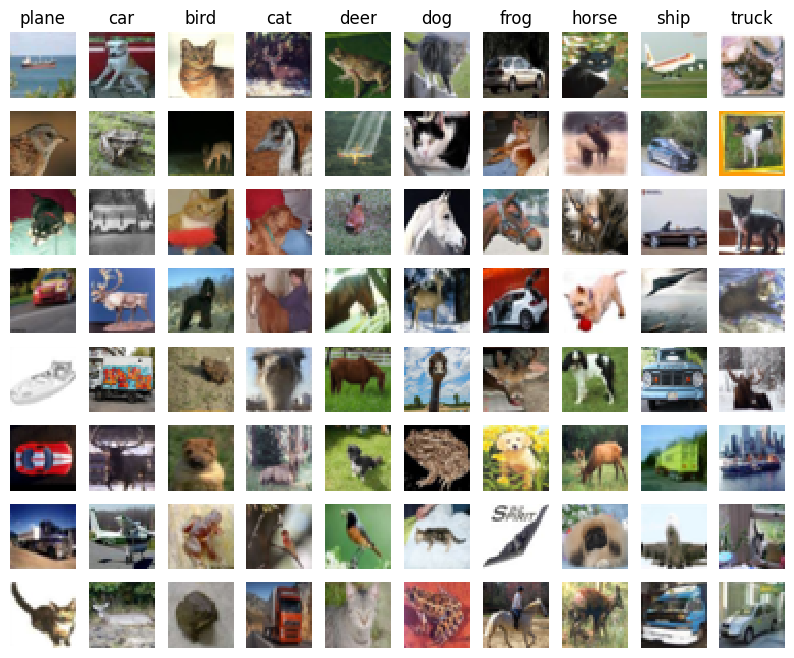

In [28]:
# An important way to gain intuition about how an algorithm works is to
# visualize the mistakes that it makes. In this visualization, we show examples
# of images that are misclassified by our current system. The first column
# shows images that our system labeled as "plane" but whose true label is
# something other than "plane".

examples_per_class = 8
classes = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
for cls, cls_name in enumerate(classes):
    idxs = np.where((y_test != cls) & (y_test_pred == cls))[0]
    idxs = np.random.choice(idxs, examples_per_class, replace=False)
    for i, idx in enumerate(idxs):
        plt.subplot(examples_per_class, len(classes), i * len(classes) + cls + 1)
        plt.imshow(X_test[idx].astype('uint8'))
        plt.axis('off')
        if i == 0:
            plt.title(cls_name)
plt.show()

### Inline question 1:
Describe the misclassification results that you see. Do they make sense?


$\color{blue}{\textit Your Answer:it makes sense because 很多错误发生在视觉上相似的类别间，HOG和颜色直方图不能充分表示物体的完整结构和空间关系，所以形状、纹理、背景或颜色相似的图片容易被混淆。}$





## Neural Network on image features
Earlier in this assigment we saw that training a two-layer neural network on raw pixels achieved better classification performance than linear classifiers on raw pixels. In this notebook we have seen that linear classifiers on image features outperform linear classifiers on raw pixels.

For completeness, we should also try training a neural network on image features. This approach should outperform all previous approaches: you should easily be able to achieve over 55% classification accuracy on the test set; our best model achieves about 60% classification accuracy.

In [29]:
# Preprocessing: Remove the bias dimension
# Make sure to run this cell only ONCE
print(X_train_feats.shape)
X_train_feats = X_train_feats[:, :-1]
X_val_feats = X_val_feats[:, :-1]
X_test_feats = X_test_feats[:, :-1]

print(X_train_feats.shape)

(49000, 170)
(49000, 169)


In [41]:
from cs231n.classifiers.fc_net import TwoLayerNet
from cs231n.solver import Solver

input_dim = X_train_feats.shape[1]
hidden_dim = 500
num_classes = 10

data = {
    'X_train': X_train_feats,
    'y_train': y_train,
    'X_val': X_val_feats,
    'y_val': y_val,
    'X_test': X_test_feats,
    'y_test': y_test,
}

net = TwoLayerNet(input_dim, hidden_dim, num_classes)
best_net = None

################################################################################
# TODO: Train a two-layer neural network on image features. You may want to    #
# cross-validate various parameters as in previous sections. Store your best   #
# model in the best_net variable.                                              #
################################################################################
solver = Solver(
    net,
    data,
    update_rule="sgd",
    optim_config={"learning_rate": 1e-1},
    lr_decay=0.95,
    num_epochs=30,
    batch_size=200,
    print_every=100,
    verbose=True,
)
solver.train()
best_net = net

(Iteration 1 / 7350) loss: 2.302571
(Epoch 0 / 30) train acc: 0.094000; val_acc: 0.107000
(Iteration 101 / 7350) loss: 2.222868
(Iteration 201 / 7350) loss: 1.653016
(Epoch 1 / 30) train acc: 0.421000; val_acc: 0.406000
(Iteration 301 / 7350) loss: 1.530634
(Iteration 401 / 7350) loss: 1.343791
(Epoch 2 / 30) train acc: 0.515000; val_acc: 0.510000
(Iteration 501 / 7350) loss: 1.426781
(Iteration 601 / 7350) loss: 1.418482
(Iteration 701 / 7350) loss: 1.341778
(Epoch 3 / 30) train acc: 0.529000; val_acc: 0.510000
(Iteration 801 / 7350) loss: 1.345936
(Iteration 901 / 7350) loss: 1.204030
(Epoch 4 / 30) train acc: 0.524000; val_acc: 0.534000
(Iteration 1001 / 7350) loss: 1.260700
(Iteration 1101 / 7350) loss: 1.346903
(Iteration 1201 / 7350) loss: 1.298198
(Epoch 5 / 30) train acc: 0.547000; val_acc: 0.539000
(Iteration 1301 / 7350) loss: 1.288447
(Iteration 1401 / 7350) loss: 1.296245
(Epoch 6 / 30) train acc: 0.567000; val_acc: 0.547000
(Iteration 1501 / 7350) loss: 1.272605
(Iteration

In [42]:
# Run your best neural net classifier on the test set. You should be able
# to get more than 58% accuracy. It is also possible to get >60% accuracy
# with careful tuning.

y_test_pred = np.argmax(best_net.loss(data['X_test']), axis=1)
test_acc = (y_test_pred == data['y_test']).mean()
print(test_acc)

0.602


In [43]:
# Save best model
best_net.save("best_two_layer_net_features.npy")

best_two_layer_net_features.npy saved.
